# 华东地区地表热流（SHF）栅格图 —— 基于论文的最小曲率插值方法

**数据**：`data/Updated heat flow data in china.csv`（中国大陆大地热流汇编，1307 条记录，GB18030 编码）
**插值方法**：Jiang et al. (2019, *Tectonophysics* 753, 36–48) *Terrestrial heat flow of continental China: Updated dataset and tectonic implications* 中介绍的方法——
> "…grid cells were created using a **minimum curvature algorithm with a tension factor of 0.5** and a grid interval of 20′ (0.3333°) latitude/longitude (Blackwell and Richards, 2004)."

即 **带张力因子的最小曲率（连续曲率张力样条）插值**，张力因子 **T = 0.5**。该方法与 GMT `surface -T0.5`（Smith & Wigner, 1990 的 continuous curvature spline in tension）实现完全一致，因此本 notebook 用 `pygmt.surface(tension=0.5)` 进行插值。
> 论文的 20′ 网格是面向全国 1:xxxx 万图件的；本图是华东区域图，默认采用 **2.5 km** 网格（`CFG['grid_spacing_km']`），方法与张力因子不变。若需严格复现论文网格间距，把 `CFG['grid_spacing_km']` 设为 37.05（≈20′）即可。

**论文中的数据筛选规则（本 notebook 同样采用）**
1. 剔除 **Category D** 数据（局部地热异常）；
2. 剔除热流值 **> 200 mW/m²** 与 **< 30 mW/m²** 的数据；
3. 论文绘制图件时还使用了研究区周边数据（"including the data from the surrounding area"）——本图取 **华东边界外扩 1° 缓冲区** 内的观测点参与插值，以保证边界处由实测数据约束而不是外推。

**绘图要求（对齐 `code/ASG-GKANWR/predict_geothermal.ipynb` 的华东区域预测栅格图）**
- 灰白地形底图（GMT earth_relief，`GrayTerrainNorm`：海平面以下纯白、陆地按高程灰阶）；底图范围比地图范围外扩 ±1.0°(经)/±0.5°(纬)，**坐标轴与参考图一致（`axis('equal')`）**，显示范围比研究区各向外扩约 0.3°，正好由外扩的地形铺满，绘图框内不会出现空白边
- 色标与参考图一致：`BoundaryNorm(np.arange(40, 105, 5), extend='both')`，即 **40–100 mW/m²、两端延伸**；标签 `SHF (mW/m²)` 用 Unicode 上标，全串 Times New Roman
- 地质构造线（TB 构造块体边界 / TLF 郯庐断裂，并裁剪到华东范围内）
- 热流栅格 **裁剪到华东区域**（`data/eastChinaLine.shp` 闭合环构成的掩膜多边形）
- 观测点散点、色标、比例尺、指北针
- **不使用克里金插值**

**新增部分**：读取 `output/train/rbfkan/combined_rasters/raster_a_shf.csv`（本研究 RBFKAN 模型预测的华东热流栅格），双线性重采样到与最小曲率栅格相同的网格后逐像元作差，绘制**差值空间分布图**（绘图格式与布局同上）。

> ⚠️ 本 notebook 只读取工作区中的既有数据文件，不修改它们；图件会内嵌显示，同时由 `CFG['save_figures']=True` 导出 PNG 到 `output/interp_mincurv_east_china/shf_mincurvature_east_china.png`（只新建文件）；栅格 CSV 需把 `CFG['save_raster']` 打开。


In [1]:
# ==================== 0. 运行环境准备 ====================
import os, sys, re, shutil, tempfile, time, warnings
from pathlib import Path

warnings.filterwarnings('ignore')


def _prepare_gmt_userdir():
    """GMT/pygmt 需要一个可写的用户目录（会话目录、瓦片缓存）。

    默认 ~/.gmt 可写时直接使用；若不可写（只读 HOME）则改到临时目录，
    并把已有的 earth_relief 瓦片缓存与数据服务器清单复制过去，避免重新下载。
    """
    home = Path.home() / '.gmt'

    def _writable(p):
        try:
            p.mkdir(parents=True, exist_ok=True)
            probe = p / '.write_probe'
            probe.touch()
            probe.unlink()
            return True
        except OSError:
            return False

    if _writable(home):
        return str(home)

    alt = Path(tempfile.gettempdir()) / 'kan_shf_gmt'
    alt.mkdir(parents=True, exist_ok=True)
    (alt / 'sessions').mkdir(exist_ok=True)
    for item in ('server', 'cache'):
        src, dst = home / item, alt / item
        if src.is_dir() and not dst.exists():
            try:
                shutil.copytree(src, dst)
            except OSError:
                pass
    for f in ('gmt_data_server.txt', 'gmt_data_server.txt.old', 'gmt_hash_server.txt'):
        if (home / f).is_file() and not (alt / f).exists():
            try:
                shutil.copy2(home / f, alt / f)
            except OSError:
                pass
    os.environ['GMT_USERDIR'] = str(alt)
    return str(alt)


GMT_HOME = _prepare_gmt_userdir()
os.environ['GMT_HISTORY'] = 'false'          # 不要把 gmt.history 写到当前目录
os.environ.setdefault('TMPDIR', tempfile.gettempdir())

import numpy as np
import pandas as pd
import pyproj

_proj_db = Path(sys.prefix) / 'Library' / 'share' / 'proj'      # conda 环境自带的 PROJ 数据库
if _proj_db.is_dir():
    try:
        pyproj.datadir.set_data_dir(str(_proj_db))
    except Exception:
        pass

import geopandas as gpd
from shapely.geometry import Point, Polygon
from shapely.ops import unary_union
from shapely.prepared import prep

import pygmt
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, Polygon as MplPolygon
from scipy.interpolate import RegularGridInterpolator

plt.rcParams['font.family'] = ['Times New Roman', 'FangSong', 'SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

print(f'pygmt {pygmt.__version__} | geopandas {gpd.__version__} | numpy {np.__version__}')
print(f'GMT user dir : {GMT_HOME}')


pygmt v0.17.0 | geopandas 1.1.4 | numpy 2.4.6
GMT user dir : C:\Users\19023\.gmt


In [2]:
# ==================== 1. 参数配置 ====================
CFG = dict(
    # ---- 输入（只读）----
    hf_csv      = r'c:\KAN-OLS-SHF\data\Updated heat flow data in china.csv',
    mask_shp    = r'c:\KAN-OLS-SHF\data\eastChinaLine.shp',          # 华东范围（117 个闭合环 -> 掩膜多边形）
    tect_shps   = {                                                   # 地质构造线
        'TB':   (r'c:\KAN-OLS-SHF\tectonicPlate\TB.shp',   'black', 2.5, '-'),
        'TLF':  (r'c:\KAN-OLS-SHF\tectonicPlate\TLF.shp',  'red',   2.5, '-'),
    },
    out_dir     = r'c:\KAN-OLS-SHF\output\interp_mincurv_east_china',
    # 机器学习（RBFKAN）预测栅格，由 code/ASG-GKANWR/predict_geothermal.ipynb 导出（列：Lon, Lat, SHF_pred）
    pred_raster_csv = r'c:\KAN-OLS-SHF\output\train\rbfkan\combined_rasters\raster_a_shf.csv',

    # ---- 数据筛选（论文规则）----
    value_mode   = 'corrected_fallback_measured',  # 'corrected' | 'measured' | 'corrected_fallback_measured'
    exclude_cats = ('D',),                          # 剔除 Category D
    hf_min       = 30.0,                            # 剔除 < 30 mW/m²
    hf_max       = 200.0,                           # 剔除 > 200 mW/m²

    # ---- 插值（论文方法）----
    tension         = 0.5,      # 最小曲率算法的张力因子（论文取值）
    grid_spacing_km = 2.5,      # 网格间距；论文全国图为 20'(≈37 km)，区域图取更细的 2.5 km
    buffer_deg      = 1.0,      # 参与插值的观测点：掩膜多边形外扩缓冲区（论文用了周边数据）

    # ---- 绘图 ----
    cmap        = 'RdYlBu_r',
    levels      = np.arange(40, 105, 5),   # 热流色阶 (mW/m²)：40–100，两端延伸 —— 与参考 notebook 完全一致
    terrain_step= 5,                        # 地形底图抽稀步长（15″ 地形每 5 个点取 1 个）
    terrain_pad = (1.0, 0.5),               # 地形底图外扩（经度, 纬度），参考 notebook 取 ±1.0°/±0.5°
    scalebar_km = 200,
    # 差值图（机器学习预测栅格 − 最小曲率插值栅格）
    diff_cmap   = 'RdBu_r',                 # 发散配色：红 = 预测偏高，蓝 = 插值偏高
    diff_levels = np.arange(-30, 35, 5),    # 以 0 为中心对称分级 ±30 mW/m²，两端延伸
    save_figures= True,    # 运行后导出 PNG 到 output/interp_mincurv_east_china/（只新建文件，不改动既有文件）
    save_raster = False,   # 打开后会写出插值栅格 / 差值栅格 CSV
)

print('张力因子 T =', CFG['tension'], '| 网格间距 =', CFG['grid_spacing_km'], 'km')


张力因子 T = 0.5 | 网格间距 = 2.5 km


In [3]:
# ==================== 2. 读取并筛选热流数据（论文规则）====================
def read_heat_flow_csv(path):
    """CSV 为 GB18030 编码（表头含全角字符），逐个编码尝试读取。"""
    last = None
    for enc in ('utf-8-sig', 'gb18030', 'gbk', 'latin-1'):
        try:
            df = pd.read_csv(path, encoding=enc)
            print(f'encoding = {enc}')
            break
        except UnicodeDecodeError as e:
            last = e
    else:
        raise last
    df.columns = [str(c).strip() for c in df.columns]
    return df


raw = read_heat_flow_csv(CFG['hf_csv'])
print('原始记录数:', len(raw))

lon = pd.to_numeric(raw['East longitude'], errors='coerce').to_numpy(float)
lat = pd.to_numeric(raw['North latitude'], errors='coerce').to_numpy(float)
hf_corr = pd.to_numeric(raw['Corrected heat flow (mW/m2)'], errors='coerce').to_numpy(float)
hf_meas = pd.to_numeric(raw['Measured Heat Flow (mW/m2)'], errors='coerce').to_numpy(float)

if CFG['value_mode'] == 'corrected':
    hf = hf_corr.copy()
elif CFG['value_mode'] == 'measured':
    hf = hf_meas.copy()
else:                                    # 优先取校正热流，缺失时用实测热流
    hf = np.where(np.isfinite(hf_corr), hf_corr, hf_meas)

cat = raw['Category'].astype(str).str.strip().str.upper().to_numpy()
keep = (np.isfinite(lon) & np.isfinite(lat) & np.isfinite(hf)
        & ~np.isin(cat, list(CFG['exclude_cats']))
        & (hf >= CFG['hf_min']) & (hf <= CFG['hf_max']))

lon, lat, hf = lon[keep], lat[keep], hf[keep]
print(f'筛选后记录数 = {len(hf)}  （剔除 Category {"/".join(CFG["exclude_cats"])}、'
      f'热流 <{CFG["hf_min"]:.0f} 或 >{CFG["hf_max"]:.0f} mW/m²）')
print(f'平均热流 = {hf.mean():.2f} ± {hf.std(ddof=1):.2f} mW/m²   '
       f'（论文全大陆结果为 61.4 ± 12.3 mW/m²，不含 Category D）')
print(f'范围 = {hf.min():.1f} ~ {hf.max():.1f} mW/m²')


encoding = gb18030
原始记录数: 1307
筛选后记录数 = 1176  （剔除 Category D、热流 <30 或 >200 mW/m²）
平均热流 = 60.24 ± 15.21 mW/m²   （论文全大陆结果为 61.4 ± 12.3 mW/m²，不含 Category D）
范围 = 30.0 ~ 140.0 mW/m²


## 华东掩膜、最小曲率插值与地形底图数据

In [4]:
# ==================== 3. 华东范围掩膜与绘图范围 ====================
gdf_mask = gpd.read_file(CFG['mask_shp'])
if gdf_mask.crs is not None and gdf_mask.crs.to_epsg() != 4326:
    gdf_mask = gdf_mask.to_crs(4326)

# eastChinaLine.shp 由 117 个闭合环（LineString）组成 -> 组成掩膜多边形
rings = [Polygon(g.coords) for g in gdf_mask.geometry if g is not None and g.is_ring]
MASK = unary_union(rings)
print('掩膜类型:', MASK.geom_type, '| 面积(平方度):', round(MASK.area, 2))

xmin, ymin, xmax, ymax = MASK.bounds
padx, pady = 0.02 * (xmax - xmin), 0.02 * (ymax - ymin)          # 与参考 notebook 相同的 2% 边距
EXT = [xmin - padx, xmax + padx, ymin - pady, ymax + pady]
print('研究区范围:', [round(v, 3) for v in EXT])

MASK_PREP = prep(MASK)
BUF_PREP = prep(MASK.buffer(CFG['buffer_deg']))

inside_obs = np.array([MASK_PREP.contains(Point(a, b)) for a, b in zip(lon, lat)])
near_obs = np.array([BUF_PREP.contains(Point(a, b)) for a, b in zip(lon, lat)])
print(f'华东范围内观测点 = {inside_obs.sum()} | 外扩 {CFG["buffer_deg"]}° 后参与插值的观测点 = {near_obs.sum()}')


掩膜类型: MultiPolygon | 面积(平方度): 75.59
研究区范围: [113.388, 123.019, 23.277, 38.697]


华东范围内观测点 = 237 | 外扩 1.0° 后参与插值的观测点 = 294


In [5]:
# ==================== 4. 最小曲率插值（张力因子 T = 0.5，论文方法）====================
# 先把经纬度投影到以研究区中心为原点的等距方位投影（AEQD，单位 km），
# 避免以"度"作欧氏距离造成各向异性；随后用 GMT surface 的张力连续曲率样条插值。
x_obs, y_obs, z_obs = lon[near_obs], lat[near_obs], hf[near_obs]
lon0, lat0 = float(np.median(x_obs)), float(np.median(y_obs))
AEQD = pyproj.Proj(f'+proj=aeqd +lat_0={lat0:.6f} +lon_0={lon0:.6f} +datum=WGS84 +units=m +no_defs')


def to_km(lon_deg, lat_deg):
    x, y = AEQD(lon_deg, lat_deg)
    return np.asarray(x) / 1000.0, np.asarray(y) / 1000.0


Xk, Yk = to_km(x_obs, y_obs)
corners = np.array([to_km(EXT[0], EXT[2]), to_km(EXT[1], EXT[2]),
                    to_km(EXT[0], EXT[3]), to_km(EXT[1], EXT[3])])
region = [corners[:, 0].min(), corners[:, 0].max(), corners[:, 1].min(), corners[:, 1].max()]

spacing = float(CFG['grid_spacing_km'])
nx = max(2, int(round((region[1] - region[0]) / spacing)))       # 让 -R 与 -I 严格整除
ny = max(2, int(round((region[3] - region[2]) / spacing)))
region = [region[0], region[0] + nx * spacing, region[2], region[2] + ny * spacing]

print(f'GMT surface: tension={CFG["tension"]}  spacing={spacing} km  '
      f'网格 {nx + 1}×{ny + 1} 个节点')
grid = pygmt.surface(x=Xk, y=Yk, z=z_obs, region=region, spacing=spacing,
                     tension=float(CFG['tension']))

gx_km = grid.coords[grid.dims[-1]].values          # x (km)
gy_km = grid.coords[grid.dims[-2]].values          # y (km)
GX_KM, GY_KM = np.meshgrid(gx_km, gy_km)
GLON, GLAT = AEQD(GX_KM * 1000.0, GY_KM * 1000.0, inverse=True)
Z_GRID = grid.values.astype(float)

# ---- 裁剪到华东范围 ----
inside_grid = np.array([MASK_PREP.contains(Point(a, b))
                        for a, b in zip(GLON.ravel(), GLAT.ravel())]).reshape(GX_KM.shape)
Z_MASK = np.where(inside_grid, Z_GRID, np.nan)
print(f'插值栅格: {Z_MASK.shape} | 华东范围内热流 '
      f'{np.nanmin(Z_MASK):.1f} ~ {np.nanmax(Z_MASK):.1f} mW/m²')

# ---- 栅格 vs 观测点 一致性检查（双线性采样）----
_rgi = RegularGridInterpolator((gy_km, gx_km), Z_GRID, method='linear',
                               bounds_error=False, fill_value=np.nan)
z_at_obs = _rgi((Yk, Xk))
ok = np.isfinite(z_at_obs)
r2 = 1.0 - np.sum((z_at_obs[ok] - z_obs[ok]) ** 2) / np.sum((z_obs[ok] - z_obs[ok].mean()) ** 2)
rmse = float(np.sqrt(np.mean((z_at_obs[ok] - z_obs[ok]) ** 2)))
print(f'栅格在观测点处的拟合: R² = {r2:.4f}, RMSE = {rmse:.2f} mW/m²  (n = {ok.sum()})')
print('注：GMT 会提示少量（约 8%）坐标重合/过密的测点被忽略，这是热流汇编中同一地点多条记录所致。')


surface [WARNING]: 24 unusable points were supplied; these will be ignored.


surface [WARNING]: You should have pre-processed the data with block-mean, -median, or -mode.


surface [WARNING]: Check that previous processing steps write results with enough decimals.


surface [WARNING]: Possibly some data were half-way between nodes and subject to IEEE 754 rounding.


GMT surface: tension=0.5  spacing=2.5 km  网格 397×688 个节点


插值栅格: (688, 397) | 华东范围内热流 32.4 ~ 93.3 mW/m²
栅格在观测点处的拟合: R² = 0.9250, RMSE = 3.23 mW/m²  (n = 287)
注：GMT 会提示少量（约 8%）坐标重合/过密的测点被忽略，这是热流汇编中同一地点多条记录所致。


In [6]:
# ==================== 5. 灰白地形底图数据（GMT earth_relief 15″）====================
# 地形范围比地图范围外扩 ±1.0°(经)/±0.5°(纬)（与参考 notebook 相同），
# 保证底图铺满整个绘图框，不会在框内出现一圈空白。
PAD_LON, PAD_LAT = CFG['terrain_pad']
REG_TERRAIN = [EXT[0] - PAD_LON, EXT[1] + PAD_LON, EXT[2] - PAD_LAT, EXT[3] + PAD_LAT]


def _tile_corner(name):
    m = re.search(r'([NS])(\d+)([EW])(\d+)', name)
    if not m:
        return None
    ns, la, ew, lo = m.group(1), int(m.group(2)), m.group(3), int(m.group(4))
    return (-lo if ew == 'W' else lo), (-la if ns == 'S' else la)


relief_dirs = [Path(GMT_HOME) / 'server' / 'earth' / 'earth_relief' / 'earth_relief_15s_p',
               Path.home() / '.gmt' / 'server' / 'earth' / 'earth_relief' / 'earth_relief_15s_p']

relief_files = []
for d in relief_dirs:
    if not d.is_dir():
        continue
    for f in sorted(d.glob('*.nc')):
        c = _tile_corner(f.name)
        if c and c[0] < REG_TERRAIN[1] and c[0] + 10 > REG_TERRAIN[0] \
                and c[1] < REG_TERRAIN[3] and c[1] + 10 > REG_TERRAIN[2]:
            relief_files.append(f)
    if relief_files:
        break

TERRAIN_LAYERS = []
step = int(CFG['terrain_step'])
try:
    import xarray as xr
    if relief_files:
        print(f'读取缓存地形瓦片 {len(relief_files)} 个: {[f.name.split(".")[0] for f in relief_files]}')
        for f in relief_files:
            da = xr.load_dataarray(str(f), engine='gmt', raster_kind='grid', region=REG_TERRAIN)
            TERRAIN_LAYERS.append((da.lon.values[::step], da.lat.values[::step],
                                   da.values[::step, ::step].astype(float)))
    else:
        print('未找到缓存瓦片，改用 pygmt.datasets.load_earth_relief（需要网络/数据服务器）')
        relief = pygmt.datasets.load_earth_relief(resolution='15s', region=REG_TERRAIN,
                                                  registration=None)
        TERRAIN_LAYERS.append((relief.lon.values[::step], relief.lat.values[::step],
                               relief.values[::step, ::step].astype(float)))
    print('地形底图分块:', [(t[0].size, t[1].size) for t in TERRAIN_LAYERS],
          '| 覆盖范围:', [round(v, 2) for v in REG_TERRAIN])
except Exception as exc:                       # 与参考 notebook 一致：地形失败不影响热流栅格
    TERRAIN_LAYERS = []
    print(f'地形加载失败，跳过灰白地形底图: {exc}')


读取缓存地形瓦片 4 个: ['N20E110', 'N20E120', 'N30E110', 'N30E120']


地形底图分块: [(366, 347), (193, 347), (366, 442), (193, 442)] | 覆盖范围: [112.39, 124.02, 22.78, 39.2]


In [7]:
# ==================== 6. 绘图辅助函数 ====================
class GrayTerrainNorm(matplotlib.colors.Normalize):
    """灰白地形配色：海平面以下纯白，陆地按高程取 0.5→0.75 灰阶（与参考 notebook 一致）。"""

    def __init__(self, vland=1500.0, gray_lo=0.5, gray_hi=0.75):
        self.vland, self.gray_lo, self.gray_hi = vland, gray_lo, gray_hi
        super().__init__(vmin=0.0, vmax=vland)

    def __call__(self, value, clip=None):
        v = np.ma.asarray(value, dtype=float)
        out = np.ma.masked_all_like(v)
        sea, land = v <= 0, v > 0
        if np.any(sea):
            out[sea] = 1.0
        if np.any(land):
            out[land] = self.gray_lo + np.clip(v[land] / self.vland, 0, 1) * (self.gray_hi - self.gray_lo)
        return out


_GRAY_NORM = GrayTerrainNorm()


def draw_gray_terrain(ax):
    """在最底层（zorder=0）绘制灰白地形底图。"""
    for tlon, tlat, tdem in TERRAIN_LAYERS:
        ax.pcolormesh(*np.meshgrid(tlon, tlat), tdem, cmap='Greys_r', norm=_GRAY_NORM,
                      shading='auto', alpha=0.9, zorder=0)


def add_scale_bar_line(ax, segment_km=200, color='black', fontsize=12):
    xl, yl = ax.get_xlim(), ax.get_ylim()
    w, h = xl[1] - xl[0], yl[1] - yl[0]
    seg = segment_km / (111.32 * np.cos(np.radians(np.mean(yl))))
    xs, yb, lh = xl[0] + 0.04 * w, yl[0] + 0.04 * h, 0.01 * h
    ax.hlines(y=yb, xmin=xs, xmax=xs + seg, colors=color, lw=1.5, clip_on=False)
    ax.vlines(x=xs, ymin=yb - lh / 2, ymax=yb + lh / 2, colors=color, lw=1.5, clip_on=False)
    ax.vlines(x=xs + seg, ymin=yb - lh / 2, ymax=yb + lh / 2, colors=color, lw=1.5, clip_on=False)
    ax.text(xs + seg / 2, yb + lh / 2 + 0.005 * h, f'{segment_km} km',
            ha='center', va='bottom', fontsize=fontsize, color=color, clip_on=False)


def add_north_arrow(ax, sr=0.02, fs=12):
    xl, yl = ax.get_xlim(), ax.get_ylim()
    w, h = xl[1] - xl[0], yl[1] - yl[0]
    x0 = xl[1] - 0.06 * w
    y0 = yl[1] - 0.06 * h - 0.02 * h
    r, al = sr * h, 0.8 * sr * h
    ax.add_patch(Circle((x0, y0), r, fc='white', ec='black', lw=1, zorder=10, clip_on=False))
    ax.add_patch(MplPolygon([(x0, y0 + al), (x0 - 0.35 * r, y0 - al), (x0 + 0.35 * r, y0 - al)],
                            fc='black', ec='none', zorder=11, clip_on=False))
    ax.text(x0, y0 + r + 0.01 * h, 'N', ha='center', va='bottom', fontsize=fs,
            fontweight='bold', color='black', clip_on=False)


def plot_mask_boundary(ax, color='0.25', lw=0.9):
    """华东范围边界（栅格裁剪边界）。"""
    b = MASK.boundary
    for line in ([b] if b.geom_type == 'LineString' else list(b.geoms)):
        xs, ys = zip(*line.coords)
        ax.plot(xs, ys, color=color, lw=lw, zorder=7)


def plot_tectonic_bdy(ax, scale=1.0):
    """绘制并裁剪到华东范围内的地质构造线（TB / TLF）。"""
    xlim_saved, ylim_saved = ax.get_xlim(), ax.get_ylim()
    for key, (path, color, lw, ls) in CFG['tect_shps'].items():
        if not os.path.exists(path):
            print(f'  [跳过] 构造线文件不存在: {path}')
            continue
        gdf = gpd.read_file(path)
        if gdf.crs is not None and gdf.crs.to_epsg() != 4326:
            gdf = gdf.to_crs(4326)
        for geom in gdf.geometry:
            if geom is None or geom.is_empty:
                continue
            g = geom.boundary if geom.geom_type in ('Polygon', 'MultiPolygon') else geom
            lines = ([g] if g.geom_type == 'LineString'
                     else list(g.geoms) if g.geom_type == 'MultiLineString' else [])
            for line in lines:
                clipped = line.intersection(MASK)
                if clipped.is_empty:
                    continue
                parts = ([clipped] if clipped.geom_type == 'LineString'
                         else list(clipped.geoms) if clipped.geom_type == 'MultiLineString' else [])
                for part in parts:
                    if part.geom_type == 'LineString':
                        xs, ys = zip(*part.coords)
                        ax.plot(xs, ys, color=color, linewidth=lw * scale, linestyle=ls, zorder=6)
    ax.set_xlim(xlim_saved)
    ax.set_ylim(ylim_saved)


TECT_LEGEND = [
    Line2D([0], [0], color='red', linewidth=2.5, label='Tancheng-Lujiang Fault'),
    Line2D([0], [0], color='black', linewidth=2.5, label='Tectonic Block boundaries'),
]
print('绘图辅助函数就绪')


绘图辅助函数就绪


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


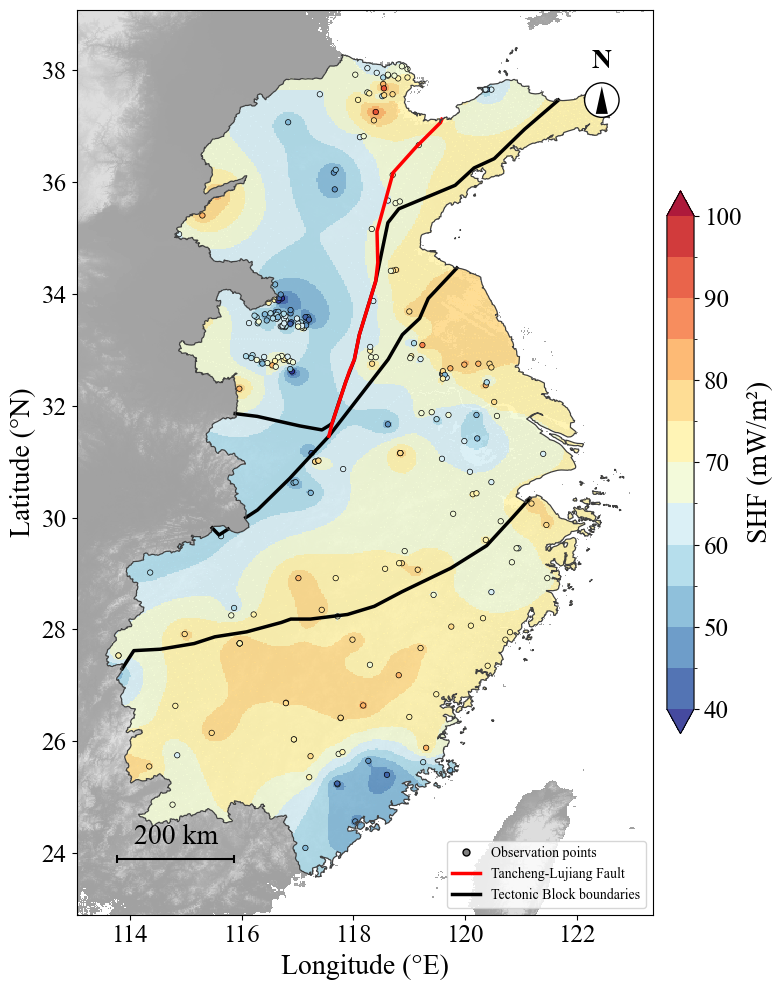

In [8]:
# ==================== 7. 华东区域地表热流预测栅格图 ====================
norm_shf = BoundaryNorm(CFG['levels'], ncolors=256, extend='both')

fig, ax = plt.subplots(figsize=(8, 10))

draw_gray_terrain(ax)                                  # 灰白地形底图（最底层，范围已外扩铺满绘图框）

mesh = ax.pcolormesh(GLON, GLAT, Z_MASK, cmap=CFG['cmap'], norm=norm_shf,
                     shading='auto', alpha=0.9, zorder=1)   # 最小曲率插值栅格（裁剪到华东）
cbar = plt.colorbar(mesh, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label('SHF (mW/m²)', fontsize=20)   # 用 Unicode 上标 ²（与参考 notebook 一致），整串标签才是 Times New Roman
cbar.ax.tick_params(labelsize=18)

ax.scatter(lon[inside_obs], lat[inside_obs], c=hf[inside_obs], cmap=CFG['cmap'], norm=norm_shf,
           s=15, ec='k', lw=0.5, zorder=5)              # 观测点

plot_mask_boundary(ax)                                  # 华东范围边界
plot_tectonic_bdy(ax)                                   # 地质构造线（裁剪到华东）

ax.set_xlabel('Longitude (°E)', fontsize=20)
ax.set_ylabel('Latitude (°N)', fontsize=20)
# 与参考 notebook 相同的坐标轴设置：axis('equal') 会按坐标轴框长宽比把显示范围略微放大
# （比研究区各向外扩约 0.3°），因此地形底图按 ±1.0°/±0.5° 外扩加载，保证绘图框内始终铺满底图、不出现空白边
ax.axis('equal')
ax.set_xlim(EXT[0], EXT[1])
ax.set_ylim(EXT[2], EXT[3])
ax.tick_params(labelsize=18)

obs_handle = Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                    markeredgecolor='k', markersize=5, label='Observation points')
ax.legend(handles=[obs_handle] + TECT_LEGEND, loc='lower right', fontsize=10, framealpha=0.8)
add_scale_bar_line(ax, CFG['scalebar_km'], fontsize=20)
add_north_arrow(ax, 0.02, 20)

plt.tight_layout()
plt.show()


## 差值空间分布图：机器学习预测栅格 − 最小曲率插值栅格

`output/train/rbfkan/combined_rasters/raster_a_shf.csv` 是本研究 RBFKAN 模型预测出的华东热流栅格（由 `code/ASG-GKANWR/predict_geothermal.ipynb` 导出，先在等距方位投影下克里金插值、再双线性加密 4 倍，列 `Lon, Lat, SHF_pred`，区域外为空白）。本节把它与前面用论文方法插出来的最小曲率栅格作对比：

1. **读取**：CSV 共 3 851 925 行 = 1925(经) × 2001(纬) 的规则网格，经纬度范围与本研究区完全一致（113.388–123.019°E / 23.277–38.697°N）；
2. **重采样**：用双线性插值（`RegularGridInterpolator`）把预测栅格采样到最小曲率栅格的同一网格（397×688，2.5 km）上，使两套栅格逐像元一一对应；
3. **作差**：`ΔSHF = 预测 − 插值`（正 = 机器学习预测偏高，负 = 最小曲率插值偏高），并沿用同一套华东掩膜裁剪；
4. **绘图**：格式与上一张图完全一致（灰白地形底图、构造线、边界、观测点、比例尺、指北针、图例、Times New Roman 字体）；配色改为以 0 为中心的对称发散色带 `RdBu_r`（±30 mW/m²，两端延伸），红色代表预测偏高。

> 观测点在差值图中改为灰色圆点（热流数值色标已不适用于差值图），位置与上图完全相同。


In [9]:
# ==================== 8. 读取机器学习预测栅格，重采样后与插值栅格作差 ====================
# 数据来源：CFG['pred_raster_csv']
#   output/train/rbfkan/combined_rasters/raster_a_shf.csv —— 由 code/ASG-GKANWR/predict_geothermal.ipynb
#   导出的 RBFKAN 预测栅格（先克里金插值、再双线性加密 4 倍），列：Lon, Lat, SHF_pred，
#   范围与本研究区一致（区域外为空白 NaN）。
t0 = time.time()
ml = pd.read_csv(CFG['pred_raster_csv'], usecols=['Lon', 'Lat', 'SHF_pred'],
                 dtype={'Lon': np.float32, 'Lat': np.float32, 'SHF_pred': np.float32})
ml_lon = np.unique(ml['Lon'].to_numpy())
ml_lat = np.unique(ml['Lat'].to_numpy())
assert len(ml) == ml_lon.size * ml_lat.size, '预测栅格存在重复坐标，无法构成规则网格'

# 按坐标索引填成规则网格（不依赖 CSV 的行序）
ML_RASTER = np.full((ml_lat.size, ml_lon.size), np.nan, dtype=np.float32)
ML_RASTER[np.searchsorted(ml_lat, ml['Lat'].to_numpy()),
          np.searchsorted(ml_lon, ml['Lon'].to_numpy())] = ml['SHF_pred'].to_numpy()
print(f'预测栅格: {ml_lon.size}×{ml_lat.size} 点（{len(ml)} 行），'
      f'经度 {ml_lon[0]:.3f}~{ml_lon[-1]:.3f}°E，纬度 {ml_lat[0]:.3f}~{ml_lat[-1]:.3f}°N，'
      f'步长 {np.diff(ml_lon).mean():.5f}°×{np.diff(ml_lat).mean():.5f}°')
print(f'  有效像元 {np.isfinite(ML_RASTER).sum()}（{100 * np.isfinite(ML_RASTER).mean():.1f}%），'
      f'热流 {np.nanmin(ML_RASTER):.1f} ~ {np.nanmax(ML_RASTER):.1f} mW/m²，读取耗时 {time.time() - t0:.1f} s')

# ---- 把预测栅格双线性插值到最小曲率栅格的同一网格上，再逐点作差 ----
_rgi_ml = RegularGridInterpolator((ml_lat.astype(float), ml_lon.astype(float)),
                                  ML_RASTER.astype(float), method='linear',
                                  bounds_error=False, fill_value=np.nan)
ML_ON_GRID = _rgi_ml((GLAT.ravel(), GLON.ravel())).reshape(GLON.shape)
DIFF = ML_ON_GRID - Z_MASK                     # 正 = 机器学习预测偏高，负 = 最小曲率插值偏高

_d = DIFF[np.isfinite(DIFF)]
_both = np.isfinite(Z_MASK) & np.isfinite(ML_ON_GRID)
print(f'差值（预测 − 插值）：n = {_d.size}，范围 {_d.min():.1f} ~ {_d.max():.1f} mW/m²，'
      f'均值 {_d.mean():.2f} ± {_d.std():.2f}')
print(f'  分位数 p2 = {np.percentile(_d, 2):.1f}，p50 = {np.percentile(_d, 50):.1f}，'
      f'p98 = {np.percentile(_d, 98):.1f}')
print(f'两种栅格在重叠区的一致性：相关系数 {np.corrcoef(Z_MASK[_both], ML_ON_GRID[_both])[0, 1]:.3f}，'
      f'RMSE {np.sqrt(np.mean((Z_MASK[_both] - ML_ON_GRID[_both]) ** 2)):.2f} mW/m²')


预测栅格: 1925×2001 点（3851925 行），经度 113.388~123.019°E，纬度 23.277~38.697°N，步长 0.00501°×0.00771°
  有效像元 1959950（50.9%），热流 40.8 ~ 119.2 mW/m²，读取耗时 1.1 s
差值（预测 − 插值）：n = 127208，范围 -22.4 ~ 59.8 mW/m²，均值 2.29 ± 9.07
  分位数 p2 = -13.7，p50 = 1.8，p98 = 29.2
两种栅格在重叠区的一致性：相关系数 0.566，RMSE 9.36 mW/m²


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


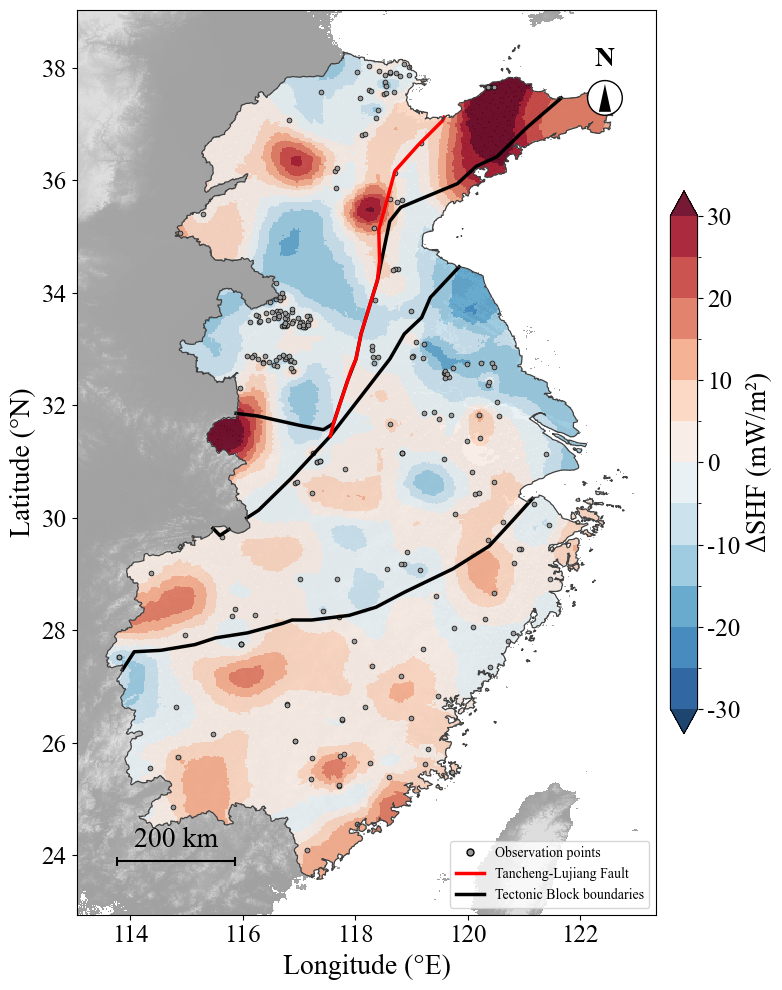

In [10]:
# ==================== 9. 差值空间分布图（机器学习预测 − 最小曲率插值）====================
# 绘图格式、布局与上一张热流栅格图完全一致：灰白地形底图 + 栅格 + 观测点 + 构造线 + 边界 + 比例尺 / 指北针 / 图例
norm_diff = BoundaryNorm(CFG['diff_levels'], ncolors=256, extend='both')

fig_diff, ax = plt.subplots(figsize=(8, 10))

draw_gray_terrain(ax)                                  # 灰白地形底图（最底层，范围已外扩铺满绘图框）

mesh = ax.pcolormesh(GLON, GLAT, DIFF, cmap=CFG['diff_cmap'], norm=norm_diff,
                     shading='auto', alpha=0.9, zorder=1)   # 差值栅格（裁剪到华东）
cbar = plt.colorbar(mesh, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label('ΔSHF (mW/m²)', fontsize=20)
cbar.ax.tick_params(labelsize=18)

ax.scatter(lon[inside_obs], lat[inside_obs], c='0.6', s=12, ec='k', lw=0.5, zorder=5)  # 观测点

plot_mask_boundary(ax)                                  # 华东范围边界
plot_tectonic_bdy(ax)                                   # 地质构造线（裁剪到华东）

ax.set_xlabel('Longitude (°E)', fontsize=20)
ax.set_ylabel('Latitude (°N)', fontsize=20)
ax.axis('equal')
ax.set_xlim(EXT[0], EXT[1])
ax.set_ylim(EXT[2], EXT[3])
ax.tick_params(labelsize=18)

obs_handle = Line2D([0], [0], marker='o', color='w', markerfacecolor='0.6',
                    markeredgecolor='k', markersize=5, label='Observation points')
ax.legend(handles=[obs_handle] + TECT_LEGEND, loc='lower right', fontsize=10, framealpha=0.8)
add_scale_bar_line(ax, CFG['scalebar_km'], fontsize=20)
add_north_arrow(ax, 0.02, 20)

plt.tight_layout()
plt.show()


In [11]:
# ==================== 10. 可选导出（默认关闭；只会新建文件，不修改既有文件）====================
if CFG['save_figures'] or CFG['save_raster']:
    out_dir = Path(CFG['out_dir'])
    out_dir.mkdir(parents=True, exist_ok=True)

    if CFG['save_figures']:
        fig.savefig(out_dir / 'shf_mincurvature_east_china.png', dpi=800, bbox_inches='tight')
        print('已保存图片:', out_dir / 'shf_mincurvature_east_china.png')
        fig_diff.savefig(out_dir / 'shf_diff_ml_minus_interp_east_china.png', dpi=800, bbox_inches='tight')
        print('已保存图片:', out_dir / 'shf_diff_ml_minus_interp_east_china.png')

    if CFG['save_raster']:
        pd.DataFrame({'Lon': GLON.ravel(), 'Lat': GLAT.ravel(), 'SHF_pred': Z_MASK.ravel()}) \
          .to_csv(out_dir / 'shf_mincurvature_raster.csv', index=False)
        print('已保存栅格:', out_dir / 'shf_mincurvature_raster.csv')
        pd.DataFrame({'Lon': GLON.ravel(), 'Lat': GLAT.ravel(), 'SHF_diff_ML_minus_interp': DIFF.ravel()}) \
          .to_csv(out_dir / 'shf_diff_ml_minus_interp_raster.csv', index=False)
        print('已保存栅格:', out_dir / 'shf_diff_ml_minus_interp_raster.csv')
else:
    print(f"未导出文件（CFG['save_figures'] / CFG['save_raster'] 均为 False）")


已保存图片: c:\KAN-OLS-SHF\output\interp_mincurv_east_china\shf_mincurvature_east_china.png


已保存图片: c:\KAN-OLS-SHF\output\interp_mincurv_east_china\shf_diff_ml_minus_interp_east_china.png


## 说明与可调项

| 项目 | 说明 |
| --- | --- |
| 插值方法 | 最小曲率（连续曲率张力样条），张力因子 **T = 0.5** —— 与论文完全一致；`pygmt.surface` 即 Smith & Wigner (1990) 的该算法实现 |
| 网格间距 | 默认 2.5 km（区域图）。论文全国图为 20′≈37 km，把 `CFG['grid_spacing_km']` 改成 **37.05** 即可严格对齐 |
| 数据取值 | `CFG['value_mode']='corrected_fallback_measured'`：优先“Corrected heat flow”，缺失时用“Measured Heat Flow”；可改为 `'corrected'` 或 `'measured'` |
| 数据筛选 | 剔除 Category D、剔除 >200 与 <30 mW/m²（论文规则） |
| 参与插值的点 | 华东掩膜外扩 1° 缓冲区内的观测点（论文使用了研究区周边数据）；把 `CFG['buffer_deg']` 设为 0 则只用区内点 |
| 掩膜 | `data/eastChinaLine.shp` 的 117 个闭合环并集 → 栅格裁剪到华东范围 |
| 色标 | `CFG['levels'] = np.arange(40, 105, 5)`（40–100 mW/m²，两端延伸），与参考 notebook 一致；标签 `SHF (mW/m²)` 用 Unicode 上标（不用 mathtext），确保为 Times New Roman |
| 显示范围 | 与参考图一致：`ax.axis('equal')`（显示范围比研究区各向外扩约 0.3°），由外扩 ±1.0°/±0.5° 的地形底图铺满 |
| 地形底图 | GMT earth_relief 15″ 灰白配色（海平面以下纯白，陆地灰阶随高程）；范围外扩 ±1.0°/±0.5° 保证铺满绘图框；读取本地瓦片缓存，失败时自动跳过 |
| 构造线 | `tectonicPlate/TB.shp`（黑，构造块体边界）、`TLF.shp`（红，郯庐断裂），均裁剪到华东范围 |
| 图例 | Observation points / Tancheng-Lujiang Fault / Tectonic Block boundaries |
| 差值图 | `ΔSHF = RBFKAN 预测栅格 − 最小曲率插值栅格`；预测栅格来自 `CFG['pred_raster_csv']`，双线性重采样到同一网格；配色 `CFG['diff_cmap']='RdBu_r'`，色阶 `CFG['diff_levels']=np.arange(-30, 35, 5)`（±30 mW/m²，两端延伸，红 = 预测偏高） |
| 输出文件 | `shf_mincurvature_east_china.png`（热流栅格图）、`shf_diff_ml_minus_interp_east_china.png`（差值图）；打开 `CFG['save_raster']` 另出两个栅格 CSV |
| 克里金 | 插值图**未使用**克里金（按要求）；仅机器学习预测栅格本身是克里金结果（由参考 notebook 生成） |

**参考**
- Jiang, G., Hu, S., Shi, Y., Zhang, C., Wang, Z., Hu, D., 2019. Terrestrial heat flow of continental China: Updated dataset and tectonic implications. *Tectonophysics* 753, 36–48.
- Blackwell, D.D., Richards, M., 2004. Geothermal Map of North America (gridding with a minimum-curvature algorithm, tension factor 0.5).
- Smith, W.H.F., Wigner, P., 1990. Gridding with continuous curvature splines in tension. *Geophysics* 55, 293–305.
- 绘图风格参照 `code/ASG-GKANWR/predict_geothermal.ipynb` 的华东区域预测栅格图。

**运行提示**：GMT 需要一个可写的用户目录；若 `~/.gmt` 只读，notebook 会自动改用临时目录并复用已有地形瓦片缓存，同时以 `GMT_HISTORY=false` 禁止写出 `gmt.history`。
